# HW05 (f) - Physical cascade and cubic-region sweep

Remove the dummy M2 and connect the actual second stage. Sweep input amplitude and choose an interval whose fundamental/IM3 slopes approach 1/3. Compare the actual cascade with the standalone-stage prediction from Eq. (2.67).

**Kernel: ECE6420 (Local).** Local **Run All** runs computation through SSH and renders plots here. Set `EXECUTION_MODE = "review"` in the setup cell to redraw saved data without SSH.

[Assignment](../references/HW5_LNA_sim_revised.pdf) | [Solution](../references/ECE6420_HW5_solution_Fall_2026.pdf)

The original IIP3 method is preserved. Its floating-point time-window boundary can omit a sample; the results include a separate coherent-window check. A single-point intercept still requires cubic-scaling validation.

In [1]:
from pathlib import Path
import sys
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for base in candidates for p in (base, base / "HW05")
             if (p / "netlists" / "reference" / "input.scs").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the Gatech-ECE6420 checkout.")
sys.path.insert(0, str(ROOT / "lib"))
from runtime import *
from remote_bridge import run_remote_parts
EXECUTION_MODE = execution_mode()  # Default: remote. Set "review" here to redraw saved data only.
RUN_SIMULATIONS = EXECUTION_MODE == "server"
if RUN_SIMULATIONS:
    preflight()
else:
    from plots import show_part, show_summary, spectrum
print("Kernel interpreter:", sys.executable)
print("Mode:", EXECUTION_MODE, "| project:", ROOT)


Kernel interpreter: /Library/Frameworks/Python.framework/Versions/3.12/bin/python3
Mode: review | project: /Users/jeonsang-eon/Gatech-ECE6420/HW05


## Parameters
These values are editable in this local kernel. The remote Run cell sends their current values to the server.

In [2]:
import math
import hw5_f as f
AMPS = [5e-3, 2.5e-3, 1.8e-3, 1.25e-3]


## Measurement helpers
Build analysis netlists from the trusted reference and parse actual Spectre ASCII traces.

In [3]:
def measure_point(amp, w1_um, l1_nh, l2_nh, rp2_ohm, cp2_ff):
    f.ATONE = amp

    f.build_netlist(
        w1_um,
        l1_nh,
        l2_nh,
        rp2_ohm,
        cp2_ff,
    )
    f.run_spectre()

    t, vout2, interstage, vinnode, vsrc = f.read_tran()

    of1 = f.tone_amp(t, vout2, f.F1)
    of2 = f.tone_amp(t, vout2, f.F2)
    oi1 = f.tone_amp(t, vout2, f.IM31)
    oi2 = f.tone_amp(t, vout2, f.IM32)

    sf1 = f.tone_amp(t, vsrc, f.F1)
    sf2 = f.tone_amp(t, vsrc, f.F2)
    mf1 = f.tone_amp(t, interstage, f.F1)
    mf2 = f.tone_amp(t, interstage, f.F2)
    nf1 = f.tone_amp(t, vinnode, f.F1)
    nf2 = f.tone_amp(t, vinnode, f.F2)

    af = f.gmean(of1, of2)
    aim = f.gmean(oi1, oi2)
    asrc = f.gmean(sf1, sf2)
    amid = f.gmean(mf1, mf2)
    anode = f.gmean(nf1, nf2)

    delta_db = 20.0 * math.log10(af / aim)

    gain_total_db = 20.0 * math.log10(af / asrc)
    gain1_db = 20.0 * math.log10(amid / asrc)
    gain2_db = 20.0 * math.log10(af / amid)
    gain_from_vinnode_db = 20.0 * math.log10(af / anode)

    input_dbv = 20.0 * math.log10(asrc)
    iip3_dbv = input_dbv + delta_db / 2.0
    iip3_vpk = 10.0 ** (iip3_dbv / 20.0)

    pin_w = asrc * asrc / (8.0 * f.RS)
    pin_dbm = 10.0 * math.log10(pin_w / 1e-3)
    iip3_dbm = pin_dbm + delta_db / 2.0

    return {
        "ATONE_nominal_Vpk": amp,
        "input_tone_measured_Vpk": asrc,
        "Vout2_fund_Vpk_geomean": af,
        "Vout2_IM3_Vpk_geomean": aim,
        "fund_minus_IM3_dB": delta_db,
        "overall_voltage_gain_dB": gain_total_db,
        "stage1_gain_inside_cascade_dB": gain1_db,
        "stage2_gain_inside_cascade_dB": gain2_db,
        "overall_gain_from_VinNode_dB": gain_from_vinnode_db,
        "IIP3_sim_Vpk": iip3_vpk,
        "IIP3_sim_dBV_peak": iip3_dbv,
        "IIP3_sim_dBm_available_50ohm": iip3_dbm,
    }

def local_slope(p_hi, p_lo, ykey):
    # Use measured input-tone amplitudes rather than the nominal setting.
    x_hi = p_hi["input_tone_measured_Vpk"]
    x_lo = p_lo["input_tone_measured_Vpk"]
    y_hi = p_hi[ykey]
    y_lo = p_lo[ykey]

    return math.log(y_hi / y_lo) / math.log(x_hi / x_lo)


## Run and plot
Run this local cell to synchronize source, compute remotely, fetch numerical data, and render the plots immediately below. Current parameter-cell values are sent to the worker.

In [4]:
if EXECUTION_MODE == "remote":
    run_remote_parts("f", {"f": {name: globals()[name] for name in ['AMPS']}})

    show_part("f")

## Server analysis
These cells execute in the server worker. A local Run delegates computation through the preceding SSH bridge; review mode uses saved numerical data.

In [5]:
if RUN_SIMULATIONS:
    meta = f.load_meta()

    c = f.require_part(meta, "c")
    d = f.require_part(meta, "d")
    e = f.require_part(meta, "e")

    cout = c["outputs"]
    dout = d["outputs"]
    eout = e["outputs"]

    w1_um = float(cout["W1_um"])
    l1_nh = float(cout["L1_nH"])

    l2_nh = float(eout["L2_nH"])
    rp2_ohm = float(eout["Rp_ohm"])
    cp2_ff = float(eout["Cp_each_fF"])

    print("HW5(f): automatic low-level two-tone sweep")
    print(
        f"Using W1={w1_um:.6f} um, "
        f"L1={l1_nh:.6f} nH, "
        f"L2={l2_nh:.6f} nH"
    )
    print()

    points = []

    for amp in AMPS:
        print(f"--- ATONE = {amp*1e3:.3f} mVpk/tone ---")
        p = measure_point(
            amp,
            w1_um,
            l1_nh,
            l2_nh,
            rp2_ohm,
            cp2_ff,
        )
        points.append(p)

        print(
            f"Gain={p['overall_voltage_gain_dB']:.3f} dB, "
            f"IM3={p['Vout2_IM3_Vpk_geomean']:.6g} Vpk, "
            f"IIP3={p['IIP3_sim_dBm_available_50ohm']:.3f} dBm"
        )
        print()

    intervals = []

    for hi, lo in zip(points[:-1], points[1:]):
        fund_slope = local_slope(
            hi,
            lo,
            "Vout2_fund_Vpk_geomean",
        )
        im3_slope = local_slope(
            hi,
            lo,
            "Vout2_IM3_Vpk_geomean",
        )

        # Ideal small-signal/cubic slopes are 1 and 3.
        # The fundamental is already extremely stable, but keep it in the score.
        score = (
            abs(fund_slope - 1.0)
            + abs(im3_slope - 3.0)
        )

        intervals.append({
            "high_ATONE_Vpk": hi["ATONE_nominal_Vpk"],
            "low_ATONE_Vpk": lo["ATONE_nominal_Vpk"],
            "fundamental_slope": fund_slope,
            "IM3_slope": im3_slope,
            "cubicity_score": score,
        })

    best_interval_index = min(
        range(len(intervals)),
        key=lambda i: intervals[i]["cubicity_score"],
    )

    best_interval = intervals[best_interval_index]

    # Use the LOWER-amplitude endpoint of the most-cubic interval:
    # it is farther below compression while still above the numerical floor.
    selected = points[best_interval_index + 1]

    # Leave f_cascade.scs corresponding to the FINAL selected point,
    # rather than the last amplitude visited by the sweep.
    f.ATONE = selected["ATONE_nominal_Vpk"]

    f.build_netlist(
        w1_um,
        l1_nh,
        l2_nh,
        rp2_ohm,
        cp2_ff,
    )

    # Eq. (2.67) prediction from standalone parts (d) and (e).
    iip3_eq267_vpk, alpha1 = f.eq267_prediction(
        dout,
        eout,
    )
    iip3_eq267_dbv = 20.0 * math.log10(iip3_eq267_vpk)

    iip3_eq267_power_w = (
        iip3_eq267_vpk * iip3_eq267_vpk
        / (8.0 * f.RS)
    )
    iip3_eq267_dbm = 10.0 * math.log10(
        iip3_eq267_power_w / 1e-3
    )

    gain_pred_db = (
        float(dout["voltage_gain_from_Fig1_vin_source_dB"])
        + float(eout["voltage_gain_dB"])
    )

    selected_gain_error_db = (
        selected["overall_voltage_gain_dB"]
        - gain_pred_db
    )

    selected_iip3_error_db = (
        selected["IIP3_sim_dBV_peak"]
        - iip3_eq267_dbv
    )

    meta["parts"]["f"] = {
        "status": "complete",
        "completed_utc": f.now(),
        "depends_on": ["c", "d", "e"],
        "method": (
            "automatic two-tone amplitude sweep; choose lower-amplitude "
            "endpoint of the adjacent interval whose measured slopes are "
            "closest to fundamental~A^1 and IM3~A^3"
        ),
        "upstream": {
            "c_W1_um": w1_um,
            "c_L1_nH": l1_nh,
            "d_gain1_dB": float(
                dout["voltage_gain_from_Fig1_vin_source_dB"]
            ),
            "d_IIP3_Vpk": float(dout["IIP3_Vpk"]),
            "e_L2_nH": l2_nh,
            "e_gain2_dB": float(eout["voltage_gain_dB"]),
            "e_IIP3_Vpk": float(eout["IIP3_Vpk"]),
        },
        "sweep": {
            "ATONE_values_Vpk": AMPS,
            "points": points,
            "local_slopes": intervals,
            "selected_interval": best_interval,
            "selection_rule": (
                "minimum |fundamental_slope-1| + |IM3_slope-3|; "
                "then use the lower-amplitude endpoint"
            ),
        },
        "outputs": {
            "selected_ATONE_Vpk": selected["ATONE_nominal_Vpk"],
            "overall_voltage_gain_dB": selected[
                "overall_voltage_gain_dB"
            ],
            "stage1_gain_inside_cascade_dB": selected[
                "stage1_gain_inside_cascade_dB"
            ],
            "stage2_gain_inside_cascade_dB": selected[
                "stage2_gain_inside_cascade_dB"
            ],
            "Vout2_fund_Vpk_geomean": selected[
                "Vout2_fund_Vpk_geomean"
            ],
            "Vout2_IM3_Vpk_geomean": selected[
                "Vout2_IM3_Vpk_geomean"
            ],
            "fund_minus_IM3_dB": selected[
                "fund_minus_IM3_dB"
            ],
            "IIP3_sim_Vpk": selected["IIP3_sim_Vpk"],
            "IIP3_sim_dBV_peak": selected[
                "IIP3_sim_dBV_peak"
            ],
            "IIP3_sim_dBm_available_50ohm": selected[
                "IIP3_sim_dBm_available_50ohm"
            ],
            "gain_pred_from_d_plus_e_dB": gain_pred_db,
            "gain_sim_minus_pred_dB": selected_gain_error_db,
            "eq267_alpha1_linear": alpha1,
            "IIP3_eq267_Vpk": iip3_eq267_vpk,
            "IIP3_eq267_dBV_peak": iip3_eq267_dbv,
            "IIP3_eq267_dBm_available_50ohm": iip3_eq267_dbm,
            "IIP3_sim_minus_eq267_dB": selected_iip3_error_db,
        },
    }

    f.save_meta(meta)

    print("===== LOCAL SLOPES =====")

    for x in intervals:
        print(
            f"{x['high_ATONE_Vpk']*1e3:.3f}"
            f" -> {x['low_ATONE_Vpk']*1e3:.3f} mV: "
            f"fund slope={x['fundamental_slope']:.3f}, "
            f"IM3 slope={x['IM3_slope']:.3f}, "
            f"score={x['cubicity_score']:.3f}"
        )

    print()
    print("===== HW5(f) FINAL AUTOMATIC SELECTION =====")
    print(
        f"Selected interval       = "
        f"{best_interval['high_ATONE_Vpk']*1e3:.3f}"
        f" -> {best_interval['low_ATONE_Vpk']*1e3:.3f} mV"
    )
    print(
        f"Selected ATONE          = "
        f"{selected['ATONE_nominal_Vpk']*1e3:.3f} mVpk/tone"
    )
    print(
        f"Overall voltage gain    = "
        f"{selected['overall_voltage_gain_dB']:.3f} dB"
    )
    print(
        f"Cascade IIP3(sim)       = "
        f"{selected['IIP3_sim_dBm_available_50ohm']:.3f} dBm"
    )
    print(
        f"Cascade IIP3(sim)       = "
        f"{selected['IIP3_sim_Vpk']:.6g} Vpk"
    )

    print()
    print("----- Comparison -----")
    print(
        f"Gain predicted (d)+(e)  = "
        f"{gain_pred_db:.3f} dB"
    )
    print(
        f"Gain sim - predicted    = "
        f"{selected_gain_error_db:+.3f} dB"
    )
    print(
        f"Eq.(2.67) IIP3          = "
        f"{iip3_eq267_dbm:.3f} dBm"
    )
    print(
        f"IIP3 sim - Eq.(2.67)    = "
        f"{selected_iip3_error_db:+.3f} dB"
    )
    print()
    print(f"metadata -> {f.META}")
else:
    print("Using numerical data from the remote bridge or review cache.")


Using numerical data from the remote bridge or review cache.


## Retain actual curves
The server exports compressed numerical traces from real PSF results. Plots are rendered by the local kernel.

In [6]:
if RUN_SIMULATIONS:
    # The sweep ends at a different amplitude. Re-run the selected point so
    # retained raw data, netlist, metadata and plots all describe the same run.
    f.run_spectre()
    t, vo, interstage, vi, vs = f.read_tran()
    save_curve("f_tran", time_s=t, Vout=vo, Interstage=interstage, VinNode=vi, VinSrc=vs)


## Local results and plots
Gain is in dB, spectra are in dBV peak, and voltage intercepts are in Vpk/dBV peak. Available input power uses Vopen-circuit,pk^2/(8*Rs). FFTs use stem plots.

| Metric | Measured value |
|---|---|
| IIP3_eq267_Vpk | 0.1048235 |
| IIP3_eq267_dBV_peak | -19.59083 |
| IIP3_eq267_dBm_available_50ohm | -15.61143 |
| IIP3_sim_Vpk | 0.1469696 |
| IIP3_sim_dBV_peak | -16.65545 |
| IIP3_sim_dBm_available_50ohm | -12.67605 |
| IIP3_sim_minus_eq267_dB | 2.935383 |
| Vout2_IM3_Vpk_geomean | 1.772565e-05 |
| Vout2_fund_Vpk_geomean | 0.06125392 |
| eq267_alpha1_linear | 7.30066 |
| fund_minus_IM3_dB | 70.77064 |
| gain_pred_from_d_plus_e_dB | 25.87091 |
| gain_sim_minus_pred_dB | 1.912537 |
| overall_voltage_gain_dB | 27.78344 |
| selected_ATONE_Vpk | 0.0025 |
| stage1_gain_inside_cascade_dB | 19.1808 |
| stage2_gain_inside_cascade_dB | 8.602648 |

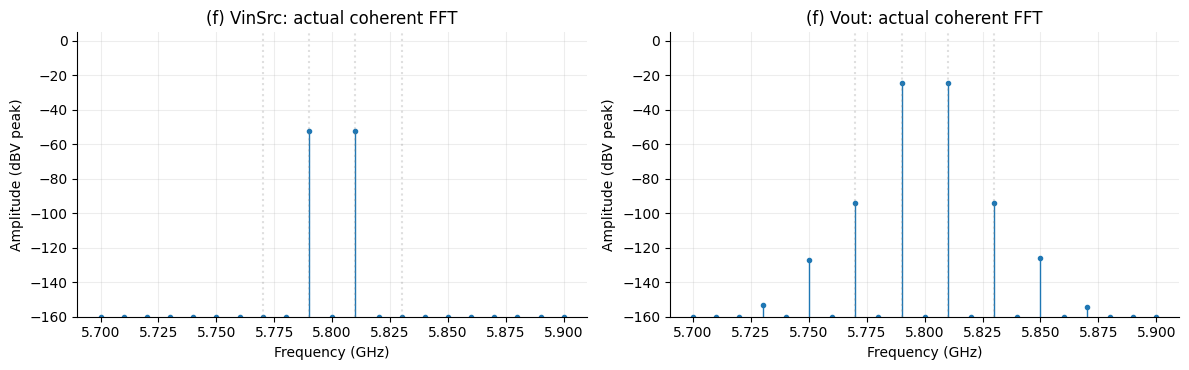

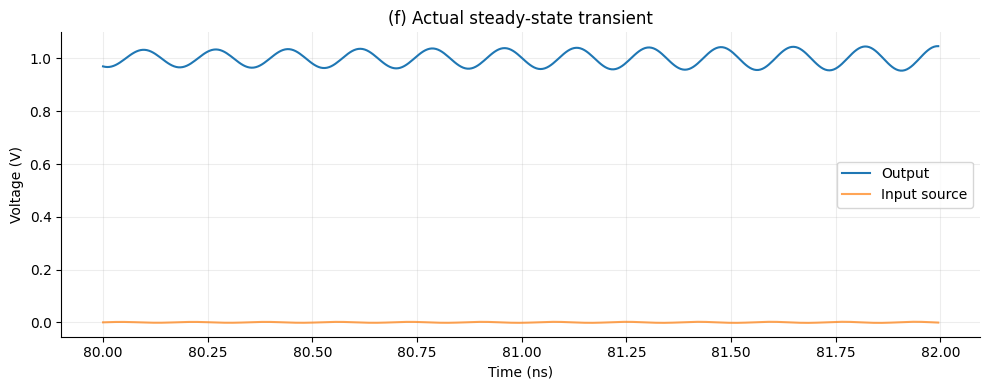

| IIP3 method | Samples | IIP3 (dBV peak) |
|---|---|---|
| Preserved submission projection | 19999 | -16.6554 |
| Exact coherent-window check | 20000 | -17.1918 |

The original window selected **19999** samples; the coherent check uses **20000** samples over exactly 100 ns. Coherent minus legacy IIP3: **-0.536 dB**. Original submission metrics remain above. The coherent single-point estimate also needs an amplitude sweep before treating it as a validated intercept.

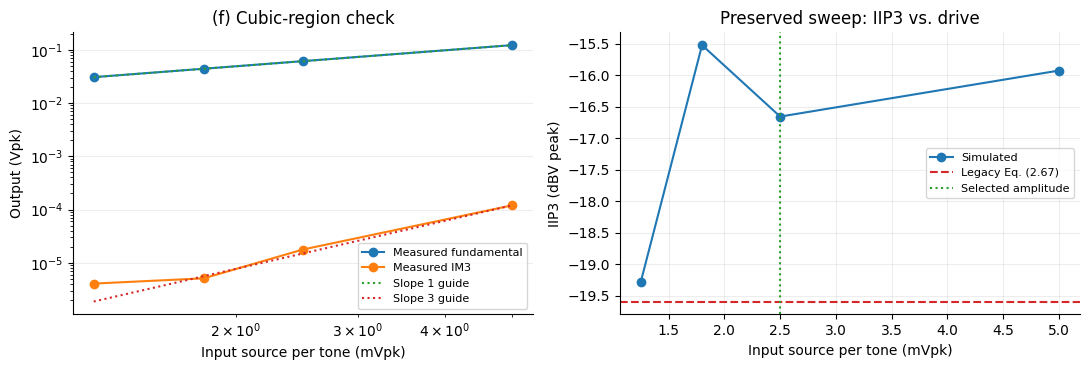

| Interval (mVpk) | Fund. slope | IM3 slope | Score |
|---|---|---|---|
| 2.5 - 5 | 0.998 | 2.755 | 0.247 |
| 1.8 - 2.5 | 0.999 | 3.794 | 0.795 |
| 1.25 - 1.8 | 1.000 | 0.624 | 2.377 |

In [7]:
if EXECUTION_MODE == "review":
    show_part("f")